# D-He3 model

In [1]:
import openmc
import numpy as np
import math
import matplotlib.pyplot as plt

In [2]:

from fusion_fuel_concepts_explorer.sources import neutron_source
from fusion_fuel_concepts_explorer.geometry import component_nodes as cn

calculate_neutron_emission_probabilities = neutron_source.calculate_neutron_emission_probabilities
res_avg = calculate_neutron_emission_probabilities(
    {"D": 0.5, "He3": 0.5},
    ion_temperature_keV=70.0,
    total_ion_density_cm3=1e14, # NOTE: density should be higher if we want to have the same power as dt
    volume_profile_cm3=1.5e6,
    reactivity_model="bosch_hale",
    include_secondary_equilibrium=True
)

average_fusion_power = res_avg.probabilities

In [3]:
fusion_power = 121e6  # W - target fusion power
eV_to_Jouls = 1.60218e-19
joules_to_mega_joules = 1e-6

# Q-values (total energy released) per reaction channel [eV]
Q_values = {
    'DHe3':  18.3e6,   # D + He3 -> He4 + p
    'DDp':    4.03e6,  # D + D -> T + p
    'DDn':    3.27e6,  # D + D -> He3 + n
    'DT':    17.6e6,   # D + T -> He4 + n
    'TT':    11.3e6,   # T + T -> He4 + 2n
    'THe3':  12.1e6,   # T + He3 -> He4 + D + n
}

# Actual reaction rates [reactions/s] from res_avg
# NOTE: reaction_rates_s['TT_rate_s'] = 2 * TT_rxn_rate (two neutrons per reaction)
rates = res_avg.reaction_rates_s
rxn_rates = {
    'DHe3':  rates['DHe3_rate_s'],
    'DDp':   rates['DDp_rate_s'],
    'DDn':   rates['DDn_2.45MeV'],    # 1 neutron/reaction
    'DT':    rates['DTn_14.1MeV'],    # 1 neutron/reaction
    'TT':    rates['TT_rate_s'] / 2,  # TT_rate_s = 2 * rxn_rate
    'THe3':  rates['THe3_rate_s'],    # 1 neutron/reaction
}

# Average energy released per fusion reaction [eV]
total_rxn_rate = sum(rxn_rates.values())
energy_per_fusion_reaction = sum(Q_values[k] * rxn_rates[k] for k in rxn_rates) / total_rxn_rate

# Average neutron energy per source neutron [eV]
# res_avg.probabilities is already normalized over neutron-producing channels
neutron_energies_eV = {
    '2.45 MeV (DDn)':    2.45e6,
    '14.1 MeV (DTn)':   14.1e6,
    '3.77 MeV (TTn)':    3.77e6,
    '4.03 MeV (THe3 n)': 4.03e6,
}
prob_dict = res_avg.probabilities
E_eV = sum(neutron_energies_eV[k] * prob_dict[k] for k in prob_dict)

number_of_neutrons_per_second = fusion_power / (energy_per_fusion_reaction * eV_to_Jouls)

print(f"Average energy per fusion reaction: {energy_per_fusion_reaction/1e6:.4f} MeV")
print(f"Average neutron energy (E_eV):      {E_eV/1e6:.4f} MeV")
print(f"Number of neutrons per second:      {number_of_neutrons_per_second:.4e}\n")

# Volume (to be calculated)
tf_coil_magnet_volume = 1
tf_coil_insulation_volume = 1
tf_coil_case_volume = 1
ybco_volume = 0.01 * tf_coil_magnet_volume  # ~1% of total (literature)


Average energy per fusion reaction: 16.5617 MeV
Average neutron energy (E_eV):      7.7854 MeV
Number of neutrons per second:      4.5600e+19



## TBR

In [4]:
sp = openmc.StatePoint("statepoint.100.h5")

tbr = sp.get_tally(name='TBR_total')
df_tbr = tbr.get_pandas_dataframe()
tbr_mean = df_tbr["mean"].sum()
tbr_std = (df_tbr["std. dev."]**2).sum()**0.5
print(f"The reactor has a TBR of {tbr_mean:.4f} ± {tbr_std:.4f}")

The reactor has a TBR of 0.7550 ± 0.0073


In [5]:
tbr_channel = sp.get_tally(name='TBR_channel')
df_tbr_c = tbr_channel.get_pandas_dataframe()
tbr_c_mean = df_tbr_c["mean"].sum()
tbr_c_std = (df_tbr_c["std. dev."]**2).sum()**0.5
print(f"The Channel has a TBR of {tbr_c_mean:.4f} ± {tbr_c_std:.4f}")

tbr_breeder = sp.get_tally(name='TBR_breeder')
df_tbr_breeder = tbr_breeder.get_pandas_dataframe()
tbr_breeder_mean = df_tbr_breeder["mean"].sum()
tbr_breeder_std = (df_tbr_breeder["std. dev."]**2).sum()**0.5
print(f"The Breeder has a TBR of {tbr_breeder_mean:.4f} ± {tbr_breeder_std:.4f}")

print(f"Sum of contributions = {tbr_c_mean+tbr_breeder_mean:.4f}")

The Channel has a TBR of 0.0927 ± 0.0007
The Breeder has a TBR of 0.6572 ± 0.0070
Sum of contributions = 0.7498


## Power deposition

In [6]:
def compute_power_and_density(name, volume):
    """
    Compute deposited power (MW) and power density (MW/m^3)
    from an OpenMC tally, including statistical uncertainty (1σ).

    Parameters
    ----------
    name : str
        Name of the tally to extract (e.g., "heating_full").
    volume : float
        Volume of the region in m^3.

    Returns
    -------
    h_MW : float
        Total deposited power in MW.
    h_std_MW : float
        Standard deviation of deposited power (MW).
    pd_MW_m3 : float
        Power density in MW/m^3.
    pd_std_MW_m3 : float
        Standard deviation of power density (MW/m^3).
    """

    # Extract the tally
    tally = sp.get_tally(name=name)

    # Mean and standard deviation arrays
    mean_vals = tally.mean.flatten()
    std_vals  = tally.std_dev.flatten()

    # Sum of means
    total_mean = mean_vals.sum()

    # Propagated std dev (quadrature)
    total_std = (std_vals**2).sum()**0.5

    # Convert to MW
    h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
    h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

    # Power density
    pd_MW_m3 = h_MW / volume
    pd_std_MW_m3 = h_std_MW / volume

    # Relative error
    rel_err = h_std_MW / h_MW if h_MW != 0 else 0.0

    # Print results
    print(f"Results for tally '{name}':")
    print(f"Power deposited: {h_MW:.3f} ± {h_std_MW:.3f} MW "
          f"({100*rel_err:.2f} %)")
    print(f"Power density:   {pd_MW_m3:.3f} ± {pd_std_MW_m3:.3f} MW/m^3\n")

    return h_MW, h_std_MW, pd_MW_m3, pd_std_MW_m3

In [7]:
h_tf_coil_magnet, h_std_tf_coil_magnet, pd_tf_coil_magnet, pd_std_tf_coil_magnet = compute_power_and_density("q_vol_tf_coil_magnet", tf_coil_magnet_volume)
h_tf_coil_insulation, h_std_tf_coil_insulation, pd_tf_coil_insulation, pd_std_tf_coil_insulation = compute_power_and_density("q_vol_tf_coil_insulation", tf_coil_insulation_volume)
h_tf_coil_case, h_std_tf_coil_case, pd_tf_coil_case, pd_std_tf_coil_case = compute_power_and_density("q_vol_tf_coil_case", tf_coil_case_volume)

Results for tally 'q_vol_tf_coil_magnet':
Power deposited: 0.001 ± 0.000 MW (11.94 %)
Power density:   0.001 ± 0.000 MW/m^3

Results for tally 'q_vol_tf_coil_insulation':
Power deposited: 0.006 ± 0.001 MW (9.50 %)
Power density:   0.006 ± 0.001 MW/m^3

Results for tally 'q_vol_tf_coil_case':
Power deposited: 0.066 ± 0.006 MW (8.90 %)
Power density:   0.066 ± 0.006 MW/m^3



In [8]:
qvol_tot = sp.get_tally(name='heating_full')

# Sum over the mean values
total_mean = qvol_tot.mean.sum()
std_vals  = qvol_tot.std_dev.flatten()
total_std = (std_vals**2).sum()**0.5

# Compute deposited power (in MW)
h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# Print results
print(f"Power deposited on the entire geometry: {h_MW:.3f} ± {h_std_MW:.3f}  MW")

Power deposited on the entire geometry: 65.735 ± 0.320  MW


In [9]:
# q_vol_tf_coil_magnet = sp.get_tally(name='q_vol_tf_coil_magnet')

# total_mean = q_vol_tf_coil_magnet.mean.sum()
# std_vals  = q_vol_tf_coil_magnet.std_dev.flatten()
# total_std = (std_vals**2).sum()**0.5

# h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
# h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# print(f"Power deposited on TF coil magnet: {h_MW:.3f} ± {h_std_MW:.3f}  MW")
# q_vol_tf_coil_insulation = sp.get_tally(name='q_vol_tf_coil_insulation')

# total_mean = q_vol_tf_coil_insulation.mean.sum()
# std_vals  = q_vol_tf_coil_insulation.std_dev.flatten()
# total_std = (std_vals**2).sum()**0.5

# h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
# h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# print(f"Power deposited on TF coil insulation: {h_MW:.3f} ± {h_std_MW:.3f}  MW")
# q_vol_tf_coil_case = sp.get_tally(name='q_vol_tf_coil_case')

# total_mean = q_vol_tf_coil_case.mean.sum()
# std_vals  = q_vol_tf_coil_case.std_dev.flatten()
# total_std = (std_vals**2).sum()**0.5

# h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
# h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# print(f"Power deposited on TF coil insulation: {h_MW:.3f} ± {h_std_MW:.3f}  MW")

## Neutron flux

In [12]:
def plot_flux_spectrum(sp, name, volume, number_of_neutrons_per_second):

    import numpy as np
    import matplotlib.pyplot as plt
    import openmc

    energy_bins = openmc.mgxs.GROUP_STRUCTURES['TRIPOLI-315']
    energy_filter = openmc.EnergyFilter(energy_bins)

    tally = sp.get_tally(name=name)

    # Convert tally results to numpy arrays
    mean = np.asarray(tally.mean)
    std  = np.asarray(tally.std_dev)

    # Determine number of energy groups and spatial bins
    n_energy = len(energy_bins) - 1
    n_cells = int(len(mean) / n_energy)

    # Reshape tally results: (cells, energy groups)
    mean = mean.reshape((n_cells, n_energy))
    std  = std.reshape((n_cells, n_energy))

    # Sum contributions from all cells
    flux = mean.sum(axis=0)

    # Propagate statistical uncertainty
    flux_std = np.sqrt((std**2).sum(axis=0))

    # Normalize flux by region volume and source strength
    flux_region = (flux / volume) * number_of_neutrons_per_second
    flux_err = (flux_std / volume) * number_of_neutrons_per_second

    # Energy axis in MeV
    E = energy_filter.values[:-1] / 1e6

    # Plot neutron flux spectrum
    plt.figure(figsize=(8,6))

    plt.step(E, flux_region, where='post', label='Neutron Flux')

    plt.fill_between(
        E,
        flux_region - 3*flux_err,
        flux_region + 3*flux_err,
        step='post',
        alpha=0.25,
        label='Flux ±3σ'
    )

    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Energy [MeV]')
    plt.ylabel('Flux [n/cm²/s]')
    plt.xlim(2e-7, 30)
    plt.grid(alpha=0.2, which='both')
    plt.legend()
    plt.title(name)
    plt.show()

    # Compute flux integrated over different energy ranges
    flux_total = flux_region.sum()
    flux_total_std = np.sqrt((flux_err**2).sum())

    flux_above_7 = flux_region[E > 7].sum()
    flux_above_7_std = np.sqrt((flux_err[E > 7]**2).sum())

    flux_1_to_7 = flux_region[(E >= 1) & (E <= 7)].sum()
    flux_1_to_7_std = np.sqrt((flux_err[(E >= 1) & (E <= 7)]**2).sum())

    flux_below_1 = flux_region[E < 1].sum()
    flux_below_1_std = np.sqrt((flux_err[E < 1]**2).sum())

    # Print flux values with uncertainty
    print(f"Total flux        = {flux_total:.3e} ± {flux_total_std:.3e} n/cm²/s")
    print(f"Flux > 7 MeV      = {flux_above_7:.3e} ± {flux_above_7_std:.3e} n/cm²/s")
    print(f"Flux 1–7 MeV      = {flux_1_to_7:.3e} ± {flux_1_to_7_std:.3e} n/cm²/s")
    print(f"Flux < 1 MeV      = {flux_below_1:.3e} ± {flux_below_1_std:.3e} n/cm²/s")

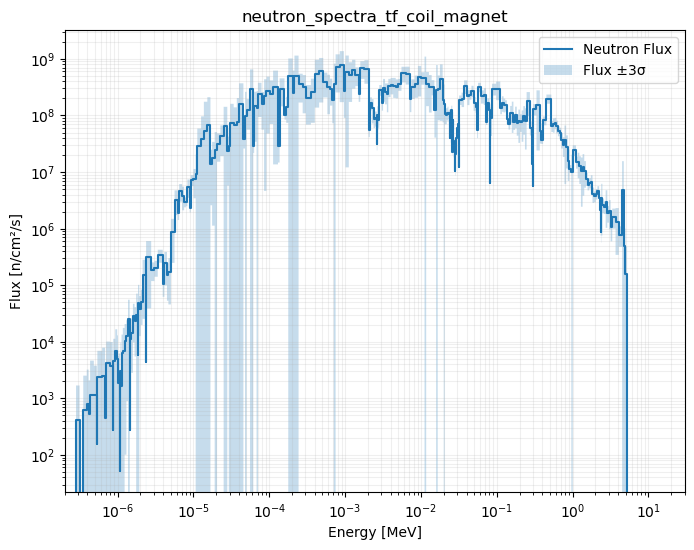

Total flux        = 3.235e+10 ± 7.455e+08 n/cm²/s
Flux > 7 MeV      = 0.000e+00 ± 0.000e+00 n/cm²/s
Flux 1–7 MeV      = 1.769e+08 ± 6.981e+06 n/cm²/s
Flux < 1 MeV      = 3.217e+10 ± 7.454e+08 n/cm²/s


In [13]:
plot_flux_spectrum(
    sp,
    name='neutron_spectra_tf_coil_magnet',
    volume=tf_coil_magnet_volume*1e6,
    number_of_neutrons_per_second=number_of_neutrons_per_second
)

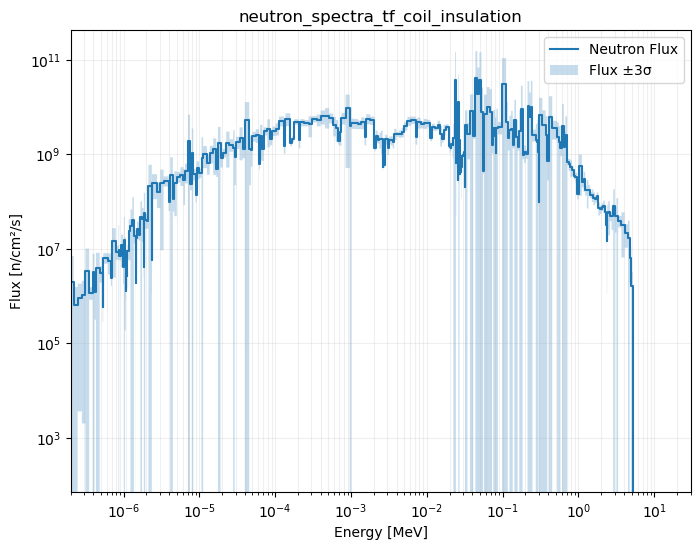

Total flux        = 6.680e+11 ± 7.339e+10 n/cm²/s
Flux > 7 MeV      = 0.000e+00 ± 0.000e+00 n/cm²/s
Flux 1–7 MeV      = 3.222e+09 ± 1.654e+08 n/cm²/s
Flux < 1 MeV      = 6.648e+11 ± 7.339e+10 n/cm²/s


In [14]:
plot_flux_spectrum(
    sp,
    name='neutron_spectra_tf_coil_insulation',
    volume=tf_coil_insulation_volume*1e6,
    number_of_neutrons_per_second=number_of_neutrons_per_second
)

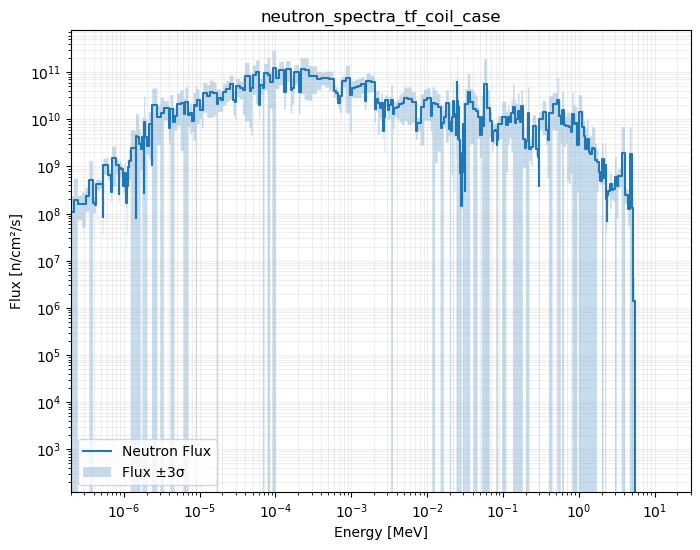

Total flux        = 5.192e+12 ± 1.458e+11 n/cm²/s
Flux > 7 MeV      = 0.000e+00 ± 0.000e+00 n/cm²/s
Flux 1–7 MeV      = 5.489e+10 ± 8.127e+09 n/cm²/s
Flux < 1 MeV      = 5.137e+12 ± 1.456e+11 n/cm²/s


In [15]:
plot_flux_spectrum(
    sp,
    name='neutron_spectra_tf_coil_case',
    volume=tf_coil_case_volume*1e6,
    number_of_neutrons_per_second=number_of_neutrons_per_second
)

## DPA

In [16]:
dpa_ybco_tally = sp.get_tally(name="dpa_ybco")
df_dpa_ybco = dpa_ybco_tally.get_pandas_dataframe()


damage_energy_in_eV = df_dpa_ybco['mean'].sum()
print('Damage energy deposited in YBCO per source neutron = ', damage_energy_in_eV, 'eV/source')

print('Two times the threshold energy of 40 eV is needed to displace an atom')
displacement_per_source_neutron = damage_energy_in_eV / (2 * 40)
print('Displacements per source neutron = ', displacement_per_source_neutron, 'eV/source')

print('Assuming 80% remanins after 20% recombine to original lattice locations')
displacements_per_source_neutron_with_recombination = displacement_per_source_neutron * 0.8
print('Displacements per source neutron after recombination = ', displacements_per_source_neutron_with_recombination, '\n')

number_of_neutrons_per_year = number_of_neutrons_per_second * 60 * 60 * 24 * 365.25
print('Number of neutrons per full power year ', number_of_neutrons_per_year)

displacements_for_all_atoms = number_of_neutrons_per_year * displacements_per_source_neutron_with_recombination
print('Displacements for all atoms in the volume ', displacements_for_all_atoms, '\n')

print('Now the number of atoms in the volume must be found to find displacements per atom (DPA)')

ybco_atomic_mass_in_g = 33.9 * 1.66054e-24

density_of_ybco_in_g_per_cm3 = 6.3

number_of_ybco_atoms = ybco_volume * density_of_ybco_in_g_per_cm3 / (ybco_atomic_mass_in_g)

print('Number of atoms on YBCO tape', number_of_ybco_atoms, '\n')

DPA = displacements_for_all_atoms / number_of_ybco_atoms
print('DPA =', DPA)

LookupError: Unable to get Tally

## Mesh

In [17]:
mesh = openmc.RegularMesh()
mesh.dimension = [128, 48, 200]
mesh.lower_left = [40, -120, -500]
mesh.upper_right = [680, 120, 500]

In [18]:
gas_production_tally = sp.get_tally(name='gas_pruduction_mesh')
tbr_tally = gas_production_tally.get_slice(scores=['(n,Xt)'])

# converts the tally result into a VTK file
mesh.write_data_to_vtk(
    filename="tbr_tally_on_reg_mesh.vtk",
    datasets={"n_Xt": tbr_tally.mean}
)

LookupError: Unable to get Tally

In [19]:
heating_tally = sp.get_tally(name='heating_mesh')

# Extract neutron-only heating
neutron_heating = heating_tally.get_slice(
    filters=[openmc.ParticleFilter],
    filter_bins=[('neutron',)]
)

# Compute total heating by summing over all particle bins
particle_filter = heating_tally.find_filter(openmc.ParticleFilter)
n_particles = len(particle_filter.bins)
n_mesh = np.prod(mesh.dimension)

data = heating_tally.mean.reshape((n_particles, n_mesh))
total_heating = data.sum(axis=0)

# Export both datasets to VTK
mesh.write_data_to_vtk(
    filename="heating_mesh.vtk",
    datasets={
        "heating_neutron": neutron_heating.mean,
        "heating_total": total_heating
    }
)

<StructuredGrid(0x55f2365c0d20) at 0x7fb1f3fdf1c0>